# Comparative Evaluation of Topological Similarity Measures for Link Prediction in the ca-GrQc Collaboration Network

**Dataset:** Stanford SNAP `ca-GrQc` (arXiv General Relativity and Quantum Cosmology collaboration network)  
**Research type:** Retrospective missing-edge prediction on a static undirected graph  
**Language:** Python  
**Notebook version:** Revised methodology, v2.0

## Research objective

This notebook evaluates five graph-theoretic link prediction measures on the ca-GrQc scientific collaboration network:

1. Common Neighbours (CN)
2. Jaccard Coefficient (JC)
3. Adamic–Adar (AA)
4. Resource Allocation (RA)
5. Preferential Attachment (PA)

The primary task is **missing-edge reconstruction**: known edges are temporarily hidden and the methods are evaluated on their ability to rank those held-out edges above sampled non-edges. Because the standard edge-list is an aggregated static graph without publication-level timestamps, this experiment is **not** a chronological forecast of future collaborations.

## What was corrected in this revision

- **Dataset audit:** report raw edge records, self-loops, duplicate undirected records, and cleaned simple-graph edges separately. Never compare a raw edge count directly with a self-loop-free graph count.
- **Sequential execution:** the notebook is self-contained and designed to run from a fresh kernel in top-to-bottom order. All saved outputs are cleared to avoid stale results.
- **Top-K metrics:** use fixed cutoffs (100, 250, 500, 1,000), not `K = number of positives`. This makes Precision@K and Recall@K different quantities.
- **Paired inference:** retain the Friedman omnibus test, add pairwise Wilcoxon signed-rank tests and Holm correction, and qualify inference because repeated splits come from one fixed graph.
- **Degree analysis:** calculate algorithm-level ROC-AUC and Average Precision within degree strata. Positive prevalence is reported only as a descriptive property of each stratum.
- **Random baseline:** evaluate a seeded random ranking on every primary split, rather than one final split only.
- **Reproducibility:** use shared candidate sets and shared tie-breaking values across methods within each split; save tables and figures to the project results directory.

> **Execution note:** Select the project environment as the Jupyter kernel, then use **Kernel → Restart Kernel and Run All Cells**. The raw dataset is downloaded only when it is not already present. All result outputs are regenerated by execution; the notebook is delivered with outputs cleared.

## Research questions

- **RQ1:** Which topological similarity measure best ranks withheld collaborations?
- **RQ2:** How does the edge holdout proportion (and resulting training density) affect performance?
- **RQ3:** How sensitive are ROC-AUC and Average Precision to the negative-sampling ratio?
- **RQ4:** Does prediction performance vary across candidate pairs with different endpoint-degree levels?
- **RQ5:** What are the relative per-candidate scoring costs of the methods?

## Notebook map

| Section | Purpose |
|---|---|
| 1 | Environment, configuration, and dataset acquisition |
| 2 | Raw-data audit and graph construction |
| 3 | Graph characterization and exploratory analysis |
| 4 | Mathematical definitions and algorithm validation |
| 5 | Leakage-safe experimental design and metrics |
| 6 | Primary repeated benchmark and random baseline |
| 7 | Summary statistics and paired post-hoc analysis |
| 8 | Holdout and negative-sampling sensitivity |
| 9 | Degree-stratified algorithm performance |
| 10 | Figures, exports, interpretation, and limitations |

## 1. Environment and experiment configuration

Install the dependencies in the selected Jupyter kernel if they are not already available:

```bash
pip install networkx numpy pandas matplotlib seaborn scipy scikit-learn jupyterlab ipykernel
```

The main experiment uses the largest connected component (LCC) because the primary benchmark concerns connected collaboration structure. The full cleaned graph is still retained for dataset-level reporting.

The primary protocol is a 20% edge holdout, 10 sampled negatives per held-out positive edge, and ten repeat seeds. Sensitivity experiments vary holdout and negative-sampling ratios.

In [1]:
# Core Python libraries
import gzip
import itertools
import math
import random
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.stats import friedmanchisquare, wilcoxon, t
from sklearn.metrics import roc_auc_score, average_precision_score

print("NetworkX:", nx.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NetworkX: 3.7
NumPy: 2.5.4
Pandas: 3.1.0


In [2]:
# Resolve the project root whether Jupyter was started from the project root or notebooks/.
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
EXPERIMENTS_DIR = RESULTS_DIR / "experiments"

for folder in [RAW_DIR, FIGURES_DIR, TABLES_DIR, EXPERIMENTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_URL = "https://snap.stanford.edu/data/ca-GrQc.txt.gz"
RAW_DATA_PATH = RAW_DIR / "ca-GrQc.txt.gz"

# Primary benchmark configuration
RANDOM_SEEDS = list(range(42, 52))  # 10 repeated random edge splits
PRIMARY_HOLDOUT = 0.20
PRIMARY_NEGATIVE_RATIO = 10
TOP_K_VALUES = (100, 250, 500, 1000)

# Sensitivity-analysis configurations
HOLDOUT_PROPORTIONS = (0.10, 0.20, 0.30, 0.40)
NEGATIVE_RATIOS = (1, 5, 10)

ALGORITHM_NAMES = ("CN", "JC", "AA", "RA", "PA")
BASELINE_NAME = "Random"

print("Project root:", PROJECT_ROOT)
print("Raw data path:", RAW_DATA_PATH)
print("Results path:", RESULTS_DIR)

Project root: D:\experimens\machine learning\graphtheory
Raw data path: D:\experimens\machine learning\graphtheory\data\raw\ca-GrQc.txt.gz
Results path: D:\experimens\machine learning\graphtheory\results


### 1.1 Acquire the official SNAP edge list

The source file is the SNAP `ca-GrQc.txt.gz` edge list. The notebook reuses an existing local copy and downloads it only when necessary. The dataset is described by SNAP as an undirected collaboration network: an edge indicates that two authors co-authored at least one paper.

In [3]:
if not RAW_DATA_PATH.exists():
    print("Downloading the ca-GrQc dataset from SNAP...")
    try:
        with urllib.request.urlopen(DATA_URL, timeout=60) as response:
            with open(RAW_DATA_PATH, "wb") as destination:
                while True:
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    destination.write(chunk)
    except Exception:
        # Remove a partial download so a later retry cannot mistake it for a valid archive.
        if RAW_DATA_PATH.exists():
            RAW_DATA_PATH.unlink()
        raise
else:
    print("Using existing local dataset:", RAW_DATA_PATH)

print(f"Dataset file size: {RAW_DATA_PATH.stat().st_size:,} bytes")

Using existing local dataset: D:\experimens\machine learning\graphtheory\data\raw\ca-GrQc.txt.gz
Dataset file size: 109,261 bytes


## 2. Raw-data audit and graph construction

### Why the audit is necessary

SNAP's catalogue reports 5,242 nodes and 14,496 edges. The raw edge-list and the cleaned simple graph are not necessarily described by the same edge-count convention. A simple undirected graph has no self-loops or repeated undirected pairs. This section measures those categories directly, rather than silently removing self-loops and retaining the raw count in the report.

For an undirected pair, `(u, v)` and `(v, u)` are treated as the same edge.

In [4]:
# Read the compressed whitespace-delimited edge list. Lines beginning with # are comments.
raw_edges_df = pd.read_csv(
    RAW_DATA_PATH,
    sep=r"\s+",
    comment="#",
    header=None,
    names=["source", "target"],
    dtype={"source": "int64", "target": "int64"},
    compression="gzip",
)

if raw_edges_df.empty or raw_edges_df.isna().any().any():
    raise ValueError("The downloaded edge list is empty or contains missing endpoints.")

raw_edge_records = len(raw_edges_df)
self_loop_mask = raw_edges_df["source"] == raw_edges_df["target"]
self_loop_records = int(self_loop_mask.sum())
non_loop_df = raw_edges_df.loc[~self_loop_mask, ["source", "target"]]

# Canonicalize each undirected pair so reversed duplicates are identified.
canonical_edges = [
    (int(u), int(v)) if int(u) < int(v) else (int(v), int(u))
    for u, v in non_loop_df.itertuples(index=False, name=None)
]
unique_undirected_edges = sorted(set(canonical_edges))
duplicate_undirected_records = len(canonical_edges) - len(unique_undirected_edges)

all_nodes = sorted(
    set(raw_edges_df["source"].astype(int))
    | set(raw_edges_df["target"].astype(int))
)

G_full = nx.Graph()
G_full.add_nodes_from(all_nodes)
G_full.add_edges_from(unique_undirected_edges)

raw_audit = pd.DataFrame(
    [
        ("Raw edge records", raw_edge_records),
        ("Self-loop records removed", self_loop_records),
        ("Repeated/reversed non-loop records removed", duplicate_undirected_records),
        ("Unique edges in cleaned simple graph", G_full.number_of_edges()),
        ("Unique vertices", G_full.number_of_nodes()),
    ],
    columns=["Audit item", "Count"],
)

raw_audit

,Audit item,Count
0,Raw edge records,28980
1,Self-loop records removed,12
2,Repeated/reversed non-loop records removed,14484
3,Unique edges in cleaned simple graph,14484
4,Unique vertices,5242


In [5]:
# Structural invariants of the cleaned graph
assert isinstance(G_full, nx.Graph) and not G_full.is_directed()
assert nx.number_of_selfloops(G_full) == 0
assert G_full.number_of_nodes() == len(all_nodes)
assert G_full.number_of_edges() == len(unique_undirected_edges)

# The SNAP catalogue reports 5,242 vertices. Keep edge counts as measured values because
# raw-record and cleaned-simple-graph conventions can differ.
if G_full.number_of_nodes() != 5242:
    warnings.warn(
        f"Expected 5,242 vertices from the SNAP catalogue; found {G_full.number_of_nodes()}. "
        "Check that the intended ca-GrQc file was loaded."
    )

print(f"Cleaned graph: {G_full.number_of_nodes():,} vertices, "
      f"{G_full.number_of_edges():,} unique non-loop undirected edges")
print("Self-loops in cleaned graph:", nx.number_of_selfloops(G_full))

Cleaned graph: 5,242 vertices, 14,484 unique non-loop undirected edges
Self-loops in cleaned graph: 0


### 2.1 Extract the largest connected component

A connected component is a maximal vertex set in which every pair of vertices is joined by a path. The LCC is selected for the primary link-prediction benchmark. The node set is retained in the training graph after edge removal, even if some nodes become isolated in a particular split.

In [6]:
components = list(nx.connected_components(G_full))
if not components:
    raise ValueError("The cleaned graph has no connected components.")

lcc_nodes = max(components, key=len)
G_lcc = G_full.subgraph(lcc_nodes).copy()

# Count raw records whose two endpoints lie in the LCC. This provides a direct audit
# comparison with the cleaned LCC edge count.
lcc_raw_record_mask = (
    raw_edges_df["source"].isin(lcc_nodes)
    & raw_edges_df["target"].isin(lcc_nodes)
)
lcc_raw_edge_records = int(lcc_raw_record_mask.sum())
lcc_self_loop_records = int(
    (lcc_raw_record_mask & self_loop_mask).sum()
)

lcc_audit = pd.DataFrame(
    [
        ("Vertices in LCC", G_lcc.number_of_nodes()),
        ("Cleaned edges in LCC", G_lcc.number_of_edges()),
        ("Raw records with both endpoints in LCC", lcc_raw_edge_records),
        ("Self-loop records inside LCC", lcc_self_loop_records),
        ("Connected components in cleaned full graph", len(components)),
        ("LCC node coverage (%)", 100 * G_lcc.number_of_nodes() / G_full.number_of_nodes()),
        ("LCC edge coverage (%)", 100 * G_lcc.number_of_edges() / G_full.number_of_edges()),
    ],
    columns=["Measurement", "Value"],
)

assert nx.is_connected(G_lcc)
assert G_lcc.number_of_nodes() <= G_full.number_of_nodes()
assert G_lcc.number_of_edges() <= G_full.number_of_edges()

lcc_audit

,Measurement,Value
0,Vertices in LCC,4158.000000
1,Cleaned edges in LCC,13422.000000
2,Raw records with both endpoints in LCC,26850.000000
3,Self-loop records inside LCC,6.000000
4,Connected components in cleaned full graph,355.000000
5,LCC node coverage (%),79.320870
6,LCC edge coverage (%),92.667771


In [7]:
# Verify the raw-to-cleaned graph representation.

non_loop_pair_counts = (
    pd.Series(canonical_edges)
    .value_counts()
)

self_loop_pairs = set(
    (int(u), int(v))
    for u, v in raw_edges_df.loc[
        self_loop_mask,
        ["source", "target"]
    ].itertuples(index=False, name=None)
)

# Validate raw records.
assert raw_edge_records == 28980

# Validate self-loops.
assert self_loop_records == 12
assert len(self_loop_pairs) == 12

# Every non-loop collaboration is recorded twice:
# once in each direction.
assert non_loop_pair_counts.eq(2).all()

# Validate the cleaned graph.
assert G_full.number_of_nodes() == 5242
assert G_full.number_of_edges() == 14484

# Reconstruct the catalogue edge counts.
assert (
    G_full.number_of_edges() + len(self_loop_pairs)
    == 14496
)

# Validate the largest connected component.
assert G_lcc.number_of_nodes() == 4158
assert G_lcc.number_of_edges() == 13422

lcc_unique_loops = sum(
    1 for u, v in self_loop_pairs
    if u in lcc_nodes and v in lcc_nodes
)

assert G_lcc.number_of_edges() + lcc_unique_loops == 13428

print("Dataset reconciliation successful.")

print("Raw records:", raw_edge_records)
print("Self-loops:", self_loop_records)
print("Unique cleaned edges:", G_full.number_of_edges())
print("LCC edges:", G_lcc.number_of_edges())

Dataset reconciliation successful.
Raw records: 28980
Self-loops: 12
Unique cleaned edges: 14484
LCC edges: 13422


### 2.2 Reconcile raw and cleaned edge counts

The earlier notebook recorded 14,496 edges before self-loop removal and 14,484 after cleaning, implying 12 self-loops. It recorded 13,422 cleaned edges in the LCC. SNAP's catalogue reports 13,428 LCC edges. This six-edge difference is consistent with six self-loop records inside the LCC. The audit below checks these quantities directly against the file instead of assuming that explanation.

Do not describe 14,496 as the number of edges in the self-loop-free graph. When citing SNAP catalogue statistics, identify them as catalogue/raw dataset statistics; when reporting computed graph metrics, identify the cleaned representation used for analysis.

In [8]:
# Dataset-level metrics on both the cleaned full graph and the LCC.
def graph_summary(G, label):
    n = G.number_of_nodes()
    m = G.number_of_edges()
    degrees = dict(G.degree())
    triangle_count = sum(nx.triangles(G).values()) // 3
    return {
        "graph": label,
        "nodes": n,
        "edges": m,
        "density": nx.density(G),
        "average_degree": (2 * m / n) if n else np.nan,
        "maximum_degree": max(degrees.values()) if degrees else 0,
        "average_clustering": nx.average_clustering(G) if n else np.nan,
        "transitivity": nx.transitivity(G) if m else np.nan,
        "triangles": triangle_count,
        "connected_components": nx.number_connected_components(G),
    }

graph_statistics_df = pd.DataFrame(
    [graph_summary(G_full, "Cleaned full graph"),
     graph_summary(G_lcc, "Largest connected component")]
).set_index("graph")

graph_statistics_df.round(6)

,nodes,edges,density,average_degree,maximum_degree,average_clustering,transitivity,triangles,connected_components
graph,,,,,,,,,
Cleaned full graph,5242,14484,0.001054,5.526135,81,0.529636,0.629842,48260,355
Largest connected component,4158,13422,0.001553,6.455988,81,0.556878,0.628894,47779,1


In [9]:
raw_audit.to_csv(TABLES_DIR / "raw_data_audit.csv", index=False)
lcc_audit.to_csv(TABLES_DIR / "lcc_audit.csv", index=False)
graph_statistics_df.to_csv(TABLES_DIR / "graph_statistics.csv")
print("Dataset audit tables saved to:", TABLES_DIR)

Dataset audit tables saved to: D:\experimens\machine learning\graphtheory\results\tables


## 3. Exploratory graph analysis

The exploratory analysis describes the topology of the cleaned LCC. Degree heterogeneity and clustering are relevant because the five prediction measures use vertex degrees and/or shared neighbours.

In [10]:
# Degree distribution on the LCC
lcc_degrees = dict(G_lcc.degree())
degree_values = np.fromiter(lcc_degrees.values(), dtype=int)
degree_summary = pd.Series(degree_values, name="degree").describe()
degree_summary

count    4158.000000
mean        6.455988
std         8.626891
min         1.000000
25%         2.000000
50%         3.000000
75%         7.000000
max        81.000000
Name: degree, dtype: float64

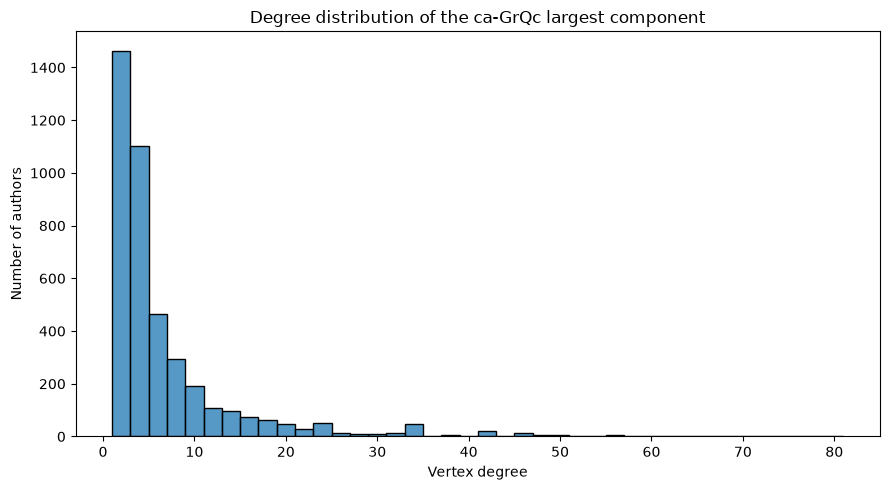

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(degree_values, bins=40, ax=ax)
ax.set(title="Degree distribution of the ca-GrQc largest component",
       xlabel="Vertex degree", ylabel="Number of authors")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "degree_distribution.png", dpi=180)
plt.show()

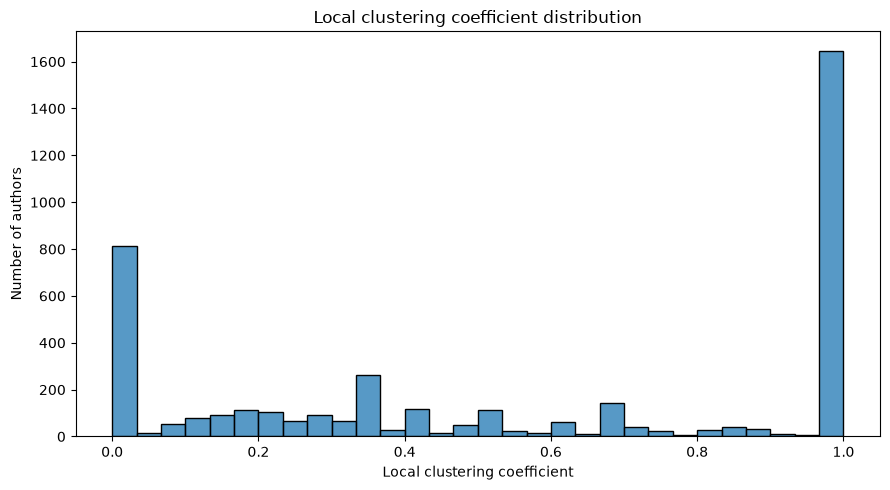

In [12]:
# Local clustering coefficient distribution on the LCC
lcc_clustering = nx.clustering(G_lcc)
clustering_values = np.fromiter(lcc_clustering.values(), dtype=float)

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(clustering_values, bins=30, ax=ax)
ax.set(title="Local clustering coefficient distribution",
       xlabel="Local clustering coefficient", ylabel="Number of authors")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "clustering_distribution.png", dpi=180)
plt.show()

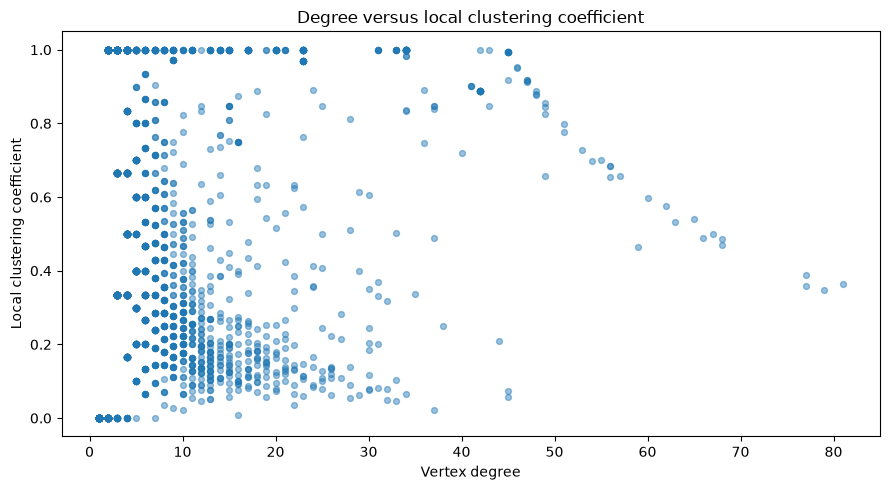

In [13]:
# Degree versus local clustering coefficient: descriptive association, not causation.
degree_clustering_df = pd.DataFrame({
    "degree": pd.Series(lcc_degrees),
    "clustering": pd.Series(lcc_clustering),
})

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(degree_clustering_df["degree"],
           degree_clustering_df["clustering"], alpha=0.45, s=18)
ax.set(title="Degree versus local clustering coefficient",
       xlabel="Vertex degree", ylabel="Local clustering coefficient")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "degree_vs_clustering.png", dpi=180)
plt.show()

### Interpretation prompts

Use the values produced above to answer these questions in your research notes:

1. Is the graph sparse or dense? Explain using density and average degree.
2. How strongly skewed is the degree distribution? Compare the median, upper quartile, and maximum.
3. What does the local clustering distribution suggest about collaboration circles?
4. Does clustering visibly increase or decrease with degree? Describe the pattern without claiming causation.
5. Why might local-neighbourhood methods be suitable for this graph, and what cases might they fail to score?

## 4. Mathematical foundations and algorithm implementation

Let the cleaned undirected graph be \(G=(V,E)\). The neighbourhood of vertex \(u\) is

\[
\Gamma(u)=\{w\in V:(u,w)\in E\},
\]

and its degree is \(d(u)=|\Gamma(u)|\). Each method assigns a score to a candidate pair \((u,v)\) not present in the training graph. Larger scores indicate stronger predicted affinity.

| Method | Definition | Structural signal |
|---|---|---|
| CN | \(|\Gamma(u)\cap\Gamma(v)|\) | Number of shared neighbours |
| JC | \(\frac{|\Gamma(u)\cap\Gamma(v)|}{|\Gamma(u)\cup\Gamma(v)|}\) | Normalized neighbourhood overlap |
| AA | \(\sum_{w\in\Gamma(u)\cap\Gamma(v)}1/\log d(w)\) | Downweights high-degree common neighbours |
| RA | \(\sum_{w\in\Gamma(u)\cap\Gamma(v)}1/d(w)\) | Resource-sharing interpretation |
| PA | \(d(u)d(v)\) | Endpoint-degree product |

For an empty Jaccard union, the implementation returns zero. Adamic–Adar skips common neighbours with degree less than or equal to one; such a node cannot be a common neighbour of two distinct vertices in a simple graph, but the guard makes the implementation numerically safe.

In [14]:
# Transparent pairwise implementations used for mathematical validation.
def common_neighbours(G, u, v):
    return len(set(G.neighbors(u)) & set(G.neighbors(v)))


def jaccard_coefficient(G, u, v):
    nu = set(G.neighbors(u))
    nv = set(G.neighbors(v))
    union_size = len(nu | nv)
    return (len(nu & nv) / union_size) if union_size else 0.0


def adamic_adar(G, u, v):
    common = set(G.neighbors(u)) & set(G.neighbors(v))
    return math.fsum(
        1.0 / math.log(G.degree(w))
        for w in common
        if G.degree(w) > 1
    )


def resource_allocation(G, u, v):
    common = set(G.neighbors(u)) & set(G.neighbors(v))
    return math.fsum(
        1.0 / G.degree(w)
        for w in common
        if G.degree(w) > 0
    )


def preferential_attachment(G, u, v):
    return G.degree(u) * G.degree(v)


PAIRWISE_ALGORITHMS = {
    "CN": common_neighbours,
    "JC": jaccard_coefficient,
    "AA": adamic_adar,
    "RA": resource_allocation,
    "PA": preferential_attachment,
}

### 4.1 Efficient scoring interface

Neighbour sets and degrees are precomputed once per training graph. The same scoring function is then used for every algorithm and candidate set. This avoids repeatedly rebuilding the graph neighbourhoods and makes the benchmark implementation easier to compare.

In [15]:
def build_graph_cache(G):
    return {
        "neighbors": {node: set(G.neighbors(node)) for node in G.nodes()},
        "degree": dict(G.degree()),
    }


def score_candidates(G, candidates, method, cache=None):
    if method not in ALGORITHM_NAMES:
        raise ValueError(f"Unknown method: {method}")

    if cache is None:
        cache = build_graph_cache(G)

    neighbors = cache["neighbors"]
    degree = cache["degree"]
    scores = np.empty(len(candidates), dtype=float)

    for index, (u, v) in enumerate(candidates):
        du, dv = degree[u], degree[v]

        if method == "PA":
            scores[index] = du * dv
            continue

        common = neighbors[u] & neighbors[v]
        cn = len(common)

        if method == "CN":
            scores[index] = cn
        elif method == "JC":
            union_size = du + dv - cn
            scores[index] = cn / union_size if union_size else 0.0
        elif method == "AA":
            scores[index] = math.fsum(
                1.0 / math.log(degree[w])
                for w in common if degree[w] > 1
            )
        elif method == "RA":
            scores[index] = math.fsum(
                1.0 / degree[w]
                for w in common if degree[w] > 0
            )

    return scores

### 4.2 Validate against a hand-checkable graph and NetworkX

A small toy graph is used first so that the expected scores can be checked manually. The same scores are then compared with NetworkX's reference link-prediction functions. This is a correctness test, not an evaluation result for ca-GrQc.

In [16]:
G_toy = nx.Graph()
G_toy.add_edges_from([(0, 2), (0, 3), (1, 2), (1, 3), (2, 4)])
toy_pair = (0, 1)

expected_toy = {
    "CN": 2.0,
    "JC": 1.0,
    "AA": 1.0 / math.log(3) + 1.0 / math.log(2),
    "RA": 1.0 / 3 + 1.0 / 2,
    "PA": 4.0,
}

for method, function in PAIRWISE_ALGORITHMS.items():
    actual = function(G_toy, *toy_pair)
    assert np.isclose(actual, expected_toy[method]), (method, actual)

print("Hand-calculated toy-graph checks passed.")

Hand-calculated toy-graph checks passed.


In [17]:
# Cross-check each implementation with NetworkX's reference predictor.
networkx_reference = {
    "JC": lambda G, e: next(nx.jaccard_coefficient(G, [e]))[2],
    "AA": lambda G, e: next(nx.adamic_adar_index(G, [e]))[2],
    "RA": lambda G, e: next(nx.resource_allocation_index(G, [e]))[2],
    "PA": lambda G, e: next(nx.preferential_attachment(G, [e]))[2],
}

for method, reference in networkx_reference.items():
    ours = PAIRWISE_ALGORITHMS[method](G_toy, *toy_pair)
    reference_score = reference(G_toy, toy_pair)
    assert np.isclose(ours, reference_score), (method, ours, reference_score)

# Common neighbours is directly exposed as a neighbour iterator in NetworkX.
assert common_neighbours(G_toy, *toy_pair) == len(list(nx.common_neighbors(G_toy, *toy_pair)))

print("NetworkX reference checks passed for all five algorithms.")

NetworkX reference checks passed for all five algorithms.


## 5. Experimental design

### 5.1 Edge holdout

For each repetition, original LCC edges are split into training and positive test edges:

\[
E=E_{train}\cup E_{test},\qquad E_{train}\cap E_{test}=\varnothing.
\]

The training graph is \(G_{train}=(V,E_{train})\). Every method scores exactly the same candidate list within a split. All vertices are retained, even if an edge deletion isolates a vertex.

### 5.2 Negative examples

A negative pair is sampled from the **non-edges of the original cleaned LCC**, not merely the non-edges of the training graph. Thus a held-out positive edge cannot accidentally be labelled negative. Negative examples are sampled rather than exhaustively enumerated.

The main candidate set uses a 10:1 negative-to-positive ratio. This is a controlled sampled evaluation distribution; its Average Precision and Precision@K are conditional on the sampled candidate pool and should not be interpreted as population prevalence or deployment precision.

In [18]:
def split_edges(G, test_size=0.20, seed=42):
    if not 0.0 < test_size < 1.0:
        raise ValueError("test_size must be strictly between 0 and 1")

    edges = sorted(
        (u, v) if u < v else (v, u)
        for u, v in G.edges()
        if u != v
    )
    if len(edges) < 2:
        raise ValueError("At least two edges are required for edge splitting")

    rng = np.random.default_rng(seed)
    n_test = max(1, int(round(test_size * len(edges))))
    if n_test >= len(edges):
        raise ValueError("The requested test split leaves no training edges")

    chosen_indices = set(
        rng.choice(len(edges), size=n_test, replace=False).tolist()
    )
    test_edges = [edge for i, edge in enumerate(edges) if i in chosen_indices]
    train_edges = [edge for i, edge in enumerate(edges) if i not in chosen_indices]

    train_graph = nx.Graph()
    train_graph.add_nodes_from(G.nodes())
    train_graph.add_edges_from(train_edges)

    return train_graph, test_edges


def sample_negative_edges(G, number, seed=42):

    nodes = sorted(G.nodes())

    n = len(nodes)

    max_non_edges = (
        n * (n - 1) // 2
        - G.number_of_edges()
    )

    if number < 0 or number > max_non_edges:
        raise ValueError(
            "Requested negative sample exceeds "
            "available non-edges."
        )

    rng = random.Random(seed)

    negatives = []
    negative_set = set()

    while len(negatives) < number:

        u, v = rng.sample(nodes, 2)

        pair = (
            (u, v) if u < v else (v, u)
        )

        if not G.has_edge(*pair) and pair not in negative_set:

            negative_set.add(pair)

            # Preserve randomized acceptance order.
            negatives.append(pair)

    return negatives


def validate_split(G_original, G_train, positives, negatives):
    positive_set = set(positives)
    negative_set = set(negatives)

    assert G_train.number_of_nodes() == G_original.number_of_nodes()
    assert positive_set.isdisjoint(negative_set)
    assert all(G_original.has_edge(u, v) for u, v in positives)
    assert all(not G_train.has_edge(u, v) for u, v in positives)
    assert all(not G_original.has_edge(u, v) for u, v in negatives)
    assert len(negative_set) == len(negatives)
    assert len(positive_set) == len(positives)
    assert G_train.number_of_edges() + len(positives) == G_original.number_of_edges()
    return True

### 5.3 Evaluation metrics

- **ROC-AUC:** probability that a randomly selected positive candidate receives a higher score than a randomly selected negative candidate (with the standard half-credit treatment for ties).
- **Average Precision (AP):** ranking quality summarized over the precision-recall curve. AP depends on the candidate-pool class ratio.
- **Precision@K:** proportion of the top K ranked candidates that are positive.
- **Recall@K:** proportion of all positive test edges recovered among the top K candidates.
- **Positive-score coverage:** proportion of positive test edges receiving a non-zero score.
- **Scoring time:** wall-clock time to score the candidate list, excluding graph-cache construction.

The top-K cutoffs are fixed values, not the number of positive examples. Consequently, Precision@K and Recall@K are not forced to be equal.

In [19]:
def precision_recall_at_k(y_true, scores, k, tie_break=None):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)

    if not 1 <= k <= len(scores):
        raise ValueError("k must be between 1 and the number of candidates")
    if y_true.sum() == 0:
        return np.nan, np.nan

    if tie_break is None:
        tie_break = np.arange(len(scores), dtype=float)

    # Primary key: descending score. Secondary key: shared deterministic tie-break values.
    ranking = np.lexsort((tie_break, -scores))
    top_k = ranking[:k]
    hits = int(y_true[top_k].sum())

    precision = hits / k
    recall = hits / int(y_true.sum())
    return precision, recall


def evaluate_candidate_set(
    train_graph,
    positive_edges,
    negative_edges,
    seed,
    top_k_values=TOP_K_VALUES,
    include_random_baseline=True,
):
    candidates = list(positive_edges) + list(negative_edges)
    y_true = np.concatenate([
        np.ones(len(positive_edges), dtype=int),
        np.zeros(len(negative_edges), dtype=int),
    ])
    if len(candidates) != len(y_true) or len(np.unique(y_true)) != 2:
        raise ValueError("Candidate set must contain both positive and negative examples")

    # Identical tie-breaking values are shared by every method in this split.
    tie_break = np.random.default_rng(seed + 700_001).random(len(candidates))
    cache = build_graph_cache(train_graph)
    records = []
    score_map = {}

    for method in ALGORITHM_NAMES:
        start = time.perf_counter()
        scores = score_candidates(train_graph, candidates, method, cache=cache)
        elapsed = time.perf_counter() - start
        score_map[method] = scores

        row = {
            "seed": seed,
            "method": method,
            "roc_auc": roc_auc_score(y_true, scores),
            "average_precision": average_precision_score(y_true, scores),
            "positive_score_coverage": float(np.mean(scores[y_true == 1] > 0)),
            "scoring_seconds": elapsed,
        }
        for k in top_k_values:
            precision, recall = precision_recall_at_k(
                y_true, scores, k, tie_break=tie_break
            )
            row[f"precision_at_{k}"] = precision
            row[f"recall_at_{k}"] = recall
        records.append(row)

    if include_random_baseline:
        random_scores = np.random.default_rng(seed + 900_001).random(len(candidates))
        baseline_row = {
            "seed": seed,
            "method": BASELINE_NAME,
            "roc_auc": roc_auc_score(y_true, random_scores),
            "average_precision": average_precision_score(y_true, random_scores),
            "positive_score_coverage": np.nan,
            "scoring_seconds": np.nan,
        }
        for k in top_k_values:
            precision, recall = precision_recall_at_k(
                y_true, random_scores, k, tie_break=tie_break
            )
            baseline_row[f"precision_at_{k}"] = precision
            baseline_row[f"recall_at_{k}"] = recall
        records.append(baseline_row)

    return pd.DataFrame(records), score_map, candidates, y_true

### 5.4 Validate the experimental pipeline on the toy graph

Before running ca-GrQc, test the split, negative sampler, candidate labels, and metric calculations on a small known graph.

In [20]:
G_pipeline_test = nx.karate_club_graph()
G_pipeline_train, pipeline_pos = split_edges(G_pipeline_test, test_size=0.20, seed=17)
pipeline_neg = sample_negative_edges(
    G_pipeline_test,
    number=len(pipeline_pos),
    seed=18,
)
assert validate_split(G_pipeline_test, G_pipeline_train, pipeline_pos, pipeline_neg)

pipeline_results, _, _, _ = evaluate_candidate_set(
    G_pipeline_train,
    pipeline_pos,
    pipeline_neg,
    seed=17,
    top_k_values=(5, 10),
)
assert set(pipeline_results["method"]) == set(ALGORITHM_NAMES) | {BASELINE_NAME}
assert (pipeline_results["precision_at_5"] >= 0).all()
assert (pipeline_results["recall_at_5"] >= 0).all()

print("Toy-graph experimental pipeline checks passed.")
pipeline_results

Toy-graph experimental pipeline checks passed.


,seed,method,roc_auc,average_precision,positive_score_coverage,scoring_seconds,precision_at_5,recall_at_5,precision_at_10,recall_at_10
0,17,CN,0.625000,0.630151,0.5625,0.000055,0.6,0.1875,0.6,0.3750
1,17,JC,0.605469,0.529331,0.5625,0.000041,0.4,0.1250,0.6,0.3750
2,17,AA,0.625000,0.606898,0.5625,0.000045,0.6,0.1875,0.6,0.3750
3,17,RA,0.632812,0.594398,0.5625,0.000040,0.8,0.2500,0.6,0.3750
4,17,PA,0.693359,0.763207,0.7500,0.000011,0.8,0.2500,0.9,0.5625
5,17,Random,0.375000,0.484333,NaN,NaN,0.4,0.1250,0.4,0.2500


## 6. Primary benchmark: 20% holdout, 10:1 negative ratio

For each seed, one training graph, one positive test set, and one negative sample are generated. All five graph methods and the random baseline are evaluated on the same candidate pairs. The random baseline is regenerated for each seed, so it is no longer a single-run comparison.

The runtime measurement covers scoring the candidate list after the graph cache has been constructed; cache construction is excluded and should be understood as a shared preprocessing cost.

In [21]:
main_records = []
degree_performance_records = []
degree_stratum_records = []
main_split_artifacts = {}

for seed in RANDOM_SEEDS:
    train_graph, positives = split_edges(
        G_lcc,
        test_size=PRIMARY_HOLDOUT,
        seed=seed,
    )
    negatives = sample_negative_edges(
        G_lcc,
        number=PRIMARY_NEGATIVE_RATIO * len(positives),
        seed=seed + 10_000,
    )
    validate_split(G_lcc, train_graph, positives, negatives)

    split_results, score_map, candidates, y_true = evaluate_candidate_set(
        train_graph,
        positives,
        negatives,
        seed=seed,
        top_k_values=TOP_K_VALUES,
        include_random_baseline=True,
    )
    main_records.extend(split_results.to_dict("records"))

    # Degree strata are based only on endpoint degrees in the training graph.
    # Bins are computed over this split's candidate pool; positive labels are not used to form bins.
    train_degree = dict(train_graph.degree())
    pair_mean_degree = np.asarray([
        (train_degree[u] + train_degree[v]) / 2.0
        for u, v in candidates
    ])
    _, bin_edges = pd.qcut(
        pair_mean_degree,
        q=4,
        retbins=True,
        duplicates="drop",
    )
    bin_ids = np.digitize(pair_mean_degree, bin_edges[1:-1], right=True)

    for bin_id in range(len(bin_edges) - 1):
        mask = bin_ids == bin_id
        y_bin = y_true[mask]
        n_pos = int(y_bin.sum())
        n_neg = int((y_bin == 0).sum())
        # Stable quartile labels allow aggregation across splits; boundaries are retained separately.
        interval_label = f"Q{bin_id + 1}"

        degree_stratum_records.append({
            "seed": seed,
            "degree_stratum": interval_label,
            "degree_lower_bound": float(bin_edges[bin_id]),
            "degree_upper_bound": float(bin_edges[bin_id + 1]),
            "candidate_count": int(mask.sum()),
            "positive_count": n_pos,
            "negative_count": n_neg,
            "positive_prevalence": float(y_bin.mean()) if len(y_bin) else np.nan,
            "mean_endpoint_degree_min": float(pair_mean_degree[mask].min()),
            "mean_endpoint_degree_max": float(pair_mean_degree[mask].max()),
        })

        for method, scores in score_map.items():
            scores_bin = scores[mask]
            if n_pos > 0 and n_neg > 0:
                auc_bin = roc_auc_score(y_bin, scores_bin)
                ap_bin = average_precision_score(y_bin, scores_bin)
            else:
                auc_bin = np.nan
                ap_bin = np.nan

            degree_performance_records.append({
                "seed": seed,
                "method": method,
                "degree_stratum": interval_label,
                "degree_lower_bound": float(bin_edges[bin_id]),
                "degree_upper_bound": float(bin_edges[bin_id + 1]),
                "candidate_count": int(mask.sum()),
                "positive_count": n_pos,
                "negative_count": n_neg,
                "roc_auc": auc_bin,
                "average_precision": ap_bin,
            })

    main_split_artifacts[seed] = {
        "train_graph": train_graph,
        "positive_edges": positives,
        "negative_edges": negatives,
    }

results_df = pd.DataFrame(main_records)
degree_performance_df = pd.DataFrame(degree_performance_records)
degree_strata_df = pd.DataFrame(degree_stratum_records)

print("Primary benchmark rows:", len(results_df))
print("Expected rows:", len(RANDOM_SEEDS) * (len(ALGORITHM_NAMES) + 1))
results_df.head(10)

Primary benchmark rows: 60
Expected rows: 60


,seed,method,roc_auc,average_precision,positive_score_coverage,scoring_seconds,precision_at_100,recall_at_100,precision_at_250,recall_at_250,precision_at_500,recall_at_500,precision_at_1000,recall_at_1000
0,42,CN,0.896935,0.798191,0.796572,0.020256,1.00,0.037258,1.000,0.093145,0.998,0.185917,0.996,0.371088
1,42,JC,0.897049,0.802060,0.796572,0.020057,0.99,0.036885,0.992,0.092399,0.994,0.185171,0.994,0.370343
2,42,AA,0.897356,0.809304,0.796572,0.038860,1.00,0.037258,1.000,0.093145,1.000,0.186289,0.999,0.372206
3,42,RA,0.897432,0.810565,0.796572,0.032104,1.00,0.037258,1.000,0.093145,1.000,0.186289,1.000,0.372578
4,42,PA,0.736535,0.426704,0.910581,0.006814,0.99,0.036885,0.944,0.087928,0.884,0.164680,0.702,0.261550
5,42,Random,0.499093,0.091175,NaN,NaN,0.10,0.003726,0.100,0.009314,0.094,0.017511,0.096,0.035768
6,43,CN,0.910049,0.822508,0.822653,0.020829,1.00,0.037258,1.000,0.093145,1.000,0.186289,0.998,0.371833
7,43,JC,0.909963,0.824206,0.822653,0.036049,0.99,0.036885,0.996,0.092772,0.998,0.185917,0.992,0.369598
8,43,AA,0.910457,0.833744,0.822653,0.061949,1.00,0.037258,1.000,0.093145,1.000,0.186289,1.000,0.372578
9,43,RA,0.910492,0.834171,0.822653,0.037258,1.00,0.037258,1.000,0.093145,1.000,0.186289,1.000,0.372578


In [22]:
# Validate primary benchmark structure and candidate protocol.
assert len(results_df) == len(RANDOM_SEEDS) * (len(ALGORITHM_NAMES) + 1)
assert results_df.groupby("seed")["method"].nunique().eq(len(ALGORITHM_NAMES) + 1).all()
assert set(results_df["method"]) == set(ALGORITHM_NAMES) | {BASELINE_NAME}
assert results_df[["roc_auc", "average_precision"]].notna().all().all()

print("Primary benchmark validation passed.")

Primary benchmark validation passed.


## 7. Summary statistics and paired statistical analysis

Report the mean and standard deviation across the ten repeated splits. The 95% t-interval below describes variability across these repeated splits on this particular network; it is not a confidence interval over a population of independent networks.

### 7.1 Mean, standard deviation, and descriptive interval

In [23]:
def mean_t_interval(values, confidence=0.95):
    values = np.asarray(pd.Series(values).dropna(), dtype=float)
    n = len(values)
    if n < 2:
        return np.nan, np.nan
    mean = float(values.mean())
    sem = float(values.std(ddof=1) / np.sqrt(n))
    critical = float(t.ppf((1 + confidence) / 2, df=n - 1))
    return mean - critical * sem, mean + critical * sem

summary_rows = []
for method, group in results_df.groupby("method", sort=False):
    row = {"method": method, "n_splits": len(group)}
    for metric in ["roc_auc", "average_precision"]:
        values = group[metric]
        lower, upper = mean_t_interval(values)
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
        row[f"{metric}_ci95_low"] = lower
        row[f"{metric}_ci95_high"] = upper
    for k in TOP_K_VALUES:
        for metric in [f"precision_at_{k}", f"recall_at_{k}"]:
            row[f"{metric}_mean"] = group[metric].mean()
            row[f"{metric}_std"] = group[metric].std(ddof=1)
    row["positive_score_coverage_mean"] = group["positive_score_coverage"].mean()
    row["scoring_seconds_mean"] = group["scoring_seconds"].mean()
    row["scoring_seconds_std"] = group["scoring_seconds"].std(ddof=1)
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).sort_values(
    "roc_auc_mean", ascending=False
).reset_index(drop=True)
summary_df.round(6)

,method,n_splits,roc_auc_mean,roc_auc_std,roc_auc_ci95_low,roc_auc_ci95_high,average_precision_mean,average_precision_std,average_precision_ci95_low,average_precision_ci95_high,...,precision_at_500_std,recall_at_500_mean,recall_at_500_std,precision_at_1000_mean,precision_at_1000_std,recall_at_1000_mean,recall_at_1000_std,positive_score_coverage_mean,scoring_seconds_mean,scoring_seconds_std
0,RA,10,0.905403,0.003589,0.902835,0.907970,0.824949,0.006464,0.820325,0.829573,...,0.000000,0.186289,0.000000,0.9999,0.000316,0.372541,0.000118,0.812444,0.035733,0.006165
1,AA,10,0.905362,0.003602,0.902785,0.907939,0.824318,0.006702,0.819523,0.829112,...,0.000000,0.186289,0.000000,0.9993,0.000949,0.372317,0.000353,0.812444,0.037242,0.009021
2,JC,10,0.904984,0.003577,0.902425,0.907542,0.816213,0.007026,0.811187,0.821239,...,0.002459,0.185618,0.000458,0.9934,0.001578,0.370119,0.000588,0.812444,0.023155,0.005782
3,CN,10,0.904942,0.003615,0.902356,0.907528,0.813053,0.006982,0.808058,0.818047,...,0.000966,0.186177,0.000180,0.9973,0.001059,0.371572,0.000395,0.812444,0.021237,0.007159
4,PA,10,0.740356,0.005874,0.736154,0.744558,0.432108,0.007987,0.426394,0.437821,...,0.014961,0.168852,0.002787,0.7101,0.017779,0.264568,0.006624,0.919001,0.007295,0.002368
5,Random,10,0.502692,0.005258,0.498930,0.506454,0.091787,0.001836,0.090473,0.093101,...,0.016007,0.016580,0.002982,0.0923,0.006929,0.034389,0.002582,NaN,NaN,NaN


### 7.2 Omnibus Friedman tests

The Friedman test checks whether the paired method scores differ overall across the repeated splits. A significant omnibus result says that not all method distributions/ranks are the same; it does **not** identify which pair differs.

In [24]:
algorithm_results_df = results_df[
    results_df["method"].isin(ALGORITHM_NAMES)
].copy()

friedman_rows = []
for metric in ["roc_auc", "average_precision"]:
    pivot = algorithm_results_df.pivot(
        index="seed", columns="method", values=metric
    ).loc[:, list(ALGORITHM_NAMES)]
    statistic, p_value = friedmanchisquare(
        *[pivot[method].to_numpy() for method in ALGORITHM_NAMES]
    )
    n, k_methods = pivot.shape
    kendall_w = statistic / (n * (k_methods - 1)) if n > 0 and k_methods > 1 else np.nan
    friedman_rows.append({
        "metric": metric,
        "friedman_statistic": statistic,
        "p_value": p_value,
        "kendalls_w": kendall_w,
        "n_splits": n,
        "n_methods": k_methods,
    })

friedman_df = pd.DataFrame(friedman_rows)
friedman_df

,metric,friedman_statistic,p_value,kendalls_w,n_splits,n_methods
0,roc_auc,38.32,9.625167e-08,0.958,10,5
1,average_precision,39.28,6.097700e-08,0.982,10,5


### 7.3 Pairwise Wilcoxon tests with Holm correction

For every pair of graph algorithms, compare the per-seed ROC-AUC and AP values using a two-sided paired Wilcoxon signed-rank test. Holm's step-down procedure controls the family-wise error rate across the pairwise comparisons for each metric.

Even after correction, interpret these p-values cautiously: all splits come from one fixed graph and overlap in their underlying edges. They are evidence about stability under this resampling procedure, not independent replications across different collaboration networks.

In [25]:
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    adjusted_sorted = np.empty(m, dtype=float)
    running_max = 0.0
    for rank, original_index in enumerate(order):
        candidate = (m - rank) * p_values[original_index]
        running_max = max(running_max, candidate)
        adjusted_sorted[rank] = min(1.0, running_max)
    adjusted = np.empty(m, dtype=float)
    for rank, original_index in enumerate(order):
        adjusted[original_index] = adjusted_sorted[rank]
    return adjusted


pairwise_rows = []
for metric in ["roc_auc", "average_precision"]:
    pivot = algorithm_results_df.pivot(
        index="seed", columns="method", values=metric
    ).loc[:, list(ALGORITHM_NAMES)]

    comparisons = list(itertools.combinations(ALGORITHM_NAMES, 2))
    raw_p_values = []
    comparison_rows = []

    for method_a, method_b in comparisons:
        a = pivot[method_a].to_numpy()
        b = pivot[method_b].to_numpy()
        differences = a - b

        if np.allclose(differences, 0.0):
            statistic, p_value = 0.0, 1.0
        else:
            test = wilcoxon(a, b, alternative="two-sided", zero_method="wilcox")
            statistic, p_value = float(test.statistic), float(test.pvalue)

        raw_p_values.append(p_value)
        comparison_rows.append({
            "metric": metric,
            "method_a": method_a,
            "method_b": method_b,
            "mean_paired_difference_a_minus_b": float(np.mean(differences)),
            "median_paired_difference_a_minus_b": float(np.median(differences)),
            "wilcoxon_statistic": statistic,
            "p_value_raw": p_value,
        })

    adjusted = holm_adjust(raw_p_values)
    for row, adjusted_p in zip(comparison_rows, adjusted):
        row["p_value_holm"] = adjusted_p
        row["significant_holm_0_05"] = bool(adjusted_p < 0.05)
        pairwise_rows.append(row)

pairwise_df = pd.DataFrame(pairwise_rows)
pairwise_df.sort_values(["metric", "p_value_holm"])

,metric,method_a,method_b,mean_paired_difference_a_minus_b,median_paired_difference_a_minus_b,wilcoxon_statistic,p_value_raw,p_value_holm,significant_holm_0_05
10,average_precision,CN,JC,-0.003160,-0.003593,1.0,0.003906,0.019531,True
11,average_precision,CN,AA,-0.011265,-0.011174,0.0,0.001953,0.019531,True
12,average_precision,CN,RA,-0.011896,-0.011862,0.0,0.001953,0.019531,True
13,average_precision,CN,PA,0.380945,0.381591,0.0,0.001953,0.019531,True
14,average_precision,JC,AA,-0.008105,-0.007843,0.0,0.001953,0.019531,True
15,average_precision,JC,RA,-0.008736,-0.008632,0.0,0.001953,0.019531,True
16,average_precision,JC,PA,0.384105,0.382846,0.0,0.001953,0.019531,True
17,average_precision,AA,RA,-0.000631,-0.000590,0.0,0.001953,0.019531,True
18,average_precision,AA,PA,0.392210,0.392995,0.0,0.001953,0.019531,True
19,average_precision,RA,PA,0.392841,0.393269,0.0,0.001953,0.019531,True


**Interpretation rule:** Only call one method statistically distinguishable from another when the corresponding Holm-adjusted p-value is below the predeclared 0.05 threshold. Also report the paired mean/median difference and its magnitude. Statistical significance alone does not establish practical importance. In particular, a very small RA–AA difference may be statistically detectable under repeated splits but still be practically negligible.

## 8. Sensitivity experiments

### 8.1 Holdout proportion

Vary the fraction of original LCC edges hidden: 10%, 20%, 30%, and 40%. For each proportion and seed, generate a new split and a 10:1 negative sample. This tests how methods behave as the training graph becomes sparser.

In [26]:
holdout_records = []
for holdout in HOLDOUT_PROPORTIONS:
    for seed in RANDOM_SEEDS:
        train_graph, positives = split_edges(
            G_lcc, test_size=holdout, seed=seed
        )
        negatives = sample_negative_edges(
            G_lcc,
            number=PRIMARY_NEGATIVE_RATIO * len(positives),
            seed=seed + 10_000,
        )
        split_results, _, _, _ = evaluate_candidate_set(
            train_graph,
            positives,
            negatives,
            seed=seed + int(holdout * 100_000),
            top_k_values=(),
            include_random_baseline=False,
        )
        for row in split_results.to_dict("records"):
            row["holdout_proportion"] = holdout
            row["training_density"] = nx.density(train_graph)
            holdout_records.append(row)

holdout_results_df = pd.DataFrame(holdout_records)
holdout_summary_df = (
    holdout_results_df
    .groupby(["holdout_proportion", "method"], as_index=False)
    .agg(
        training_density_mean=("training_density", "mean"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        ap_mean=("average_precision", "mean"),
        ap_std=("average_precision", "std"),
    )
)
holdout_summary_df.round(6)

,holdout_proportion,method,training_density_mean,roc_auc_mean,roc_auc_std,ap_mean,ap_std
0,0.1,AA,0.001398,0.933696,0.005478,0.875347,0.009981
1,0.1,CN,0.001398,0.933209,0.005489,0.863216,0.010374
2,0.1,JC,0.001398,0.933245,0.005465,0.866959,0.010155
3,0.1,PA,0.001398,0.743415,0.008170,0.433596,0.011578
4,0.1,RA,0.001398,0.933749,0.005479,0.876093,0.010056
5,0.2,AA,0.001242,0.905362,0.003602,0.824318,0.006702
6,0.2,CN,0.001242,0.904942,0.003615,0.813053,0.006982
7,0.2,JC,0.001242,0.904984,0.003577,0.816213,0.007026
8,0.2,PA,0.001242,0.740356,0.005874,0.432108,0.007987
9,0.2,RA,0.001242,0.905403,0.003589,0.824949,0.006464


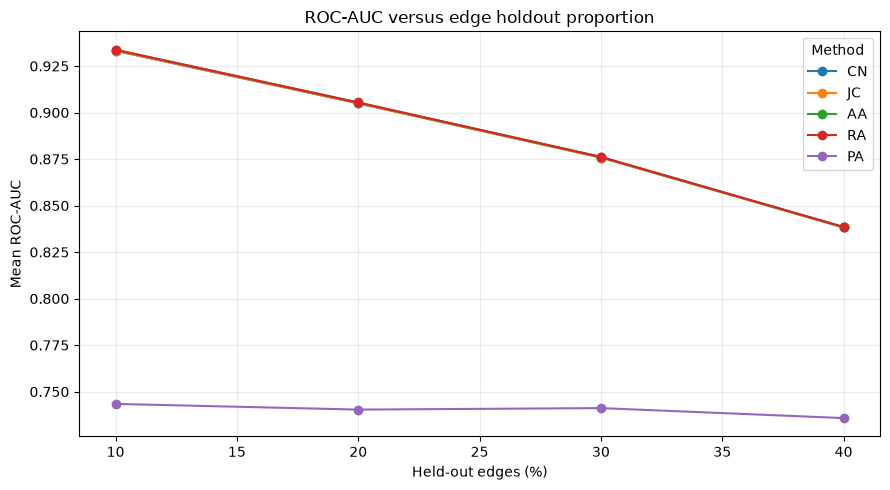

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
for method in ALGORITHM_NAMES:
    subset = holdout_summary_df[holdout_summary_df["method"] == method]
    ax.plot(
        subset["holdout_proportion"] * 100,
        subset["roc_auc_mean"],
        marker="o",
        label=method,
    )
ax.set(
    title="ROC-AUC versus edge holdout proportion",
    xlabel="Held-out edges (%)",
    ylabel="Mean ROC-AUC",
)
ax.legend(title="Method")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "holdout_sensitivity.png", dpi=180)
plt.show()

### 8.2 Negative-sampling ratio

Using the same positive test set for a given seed, vary the number of sampled negatives per positive edge (1:1, 5:1, and 10:1). The negative pools are nested within each seed: one reproducible maximum pool is sampled, then prefixes are used for each ratio. This isolates the effect of candidate-pool class balance more clearly than drawing unrelated negative sets for every ratio.

In [28]:
negative_ratio_records = []
for seed in RANDOM_SEEDS:
    train_graph, positives = split_edges(
        G_lcc,
        test_size=PRIMARY_HOLDOUT,
        seed=seed,
    )
    max_negative_pool = sample_negative_edges(
        G_lcc,
        number=max(NEGATIVE_RATIOS) * len(positives),
        seed=seed + 10_000,
    )

    for ratio in NEGATIVE_RATIOS:
        negatives = max_negative_pool[:ratio * len(positives)]
        split_results, _, _, _ = evaluate_candidate_set(
            train_graph,
            positives,
            negatives,
            seed=seed + ratio * 100_000,
            top_k_values=(),
            include_random_baseline=False,
        )
        for row in split_results.to_dict("records"):
            row["negative_ratio"] = ratio
            negative_ratio_records.append(row)

negative_ratio_results_df = pd.DataFrame(negative_ratio_records)
negative_ratio_summary_df = (
    negative_ratio_results_df
    .groupby(["negative_ratio", "method"], as_index=False)
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        ap_mean=("average_precision", "mean"),
        ap_std=("average_precision", "std"),
    )
)
negative_ratio_summary_df.round(6)

,negative_ratio,method,roc_auc_mean,roc_auc_std,ap_mean,ap_std
0,1,AA,0.905337,0.003589,0.905647,0.003577
1,1,CN,0.904923,0.003581,0.904465,0.003579
2,1,JC,0.904870,0.003499,0.904465,0.003154
3,1,PA,0.739827,0.006334,0.789047,0.005634
4,1,RA,0.905378,0.003594,0.905711,0.003576
5,5,AA,0.905391,0.003602,0.841199,0.005981
6,5,CN,0.904985,0.003633,0.835544,0.006265
7,5,JC,0.904989,0.003570,0.836969,0.005731
8,5,PA,0.740763,0.006213,0.537480,0.007409
9,5,RA,0.905430,0.003587,0.841496,0.005878


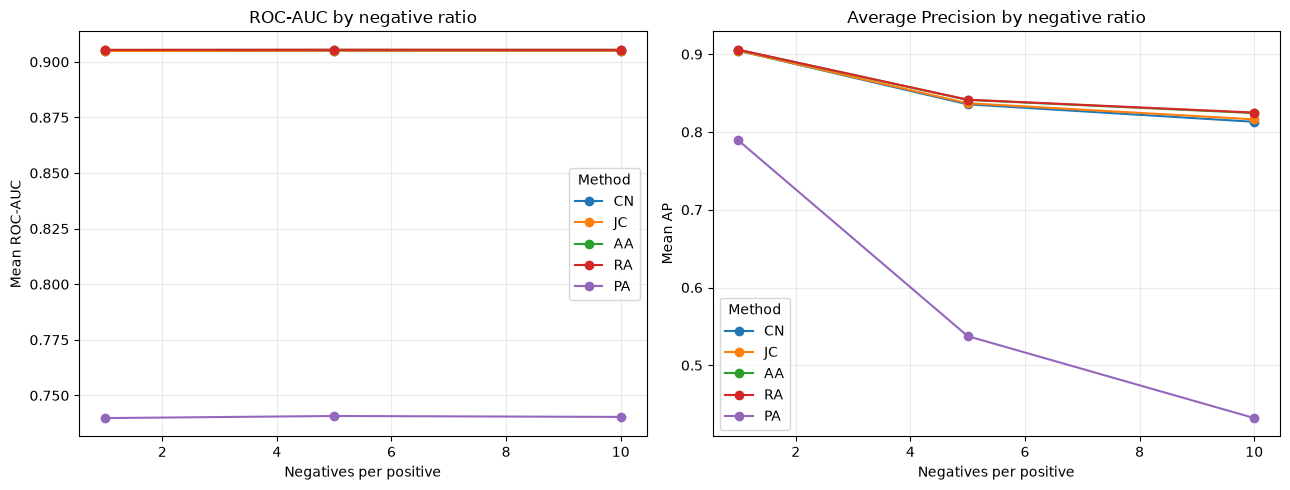

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for method in ALGORITHM_NAMES:
    subset = negative_ratio_summary_df[
        negative_ratio_summary_df["method"] == method
    ]
    axes[0].plot(subset["negative_ratio"], subset["roc_auc_mean"], marker="o", label=method)
    axes[1].plot(subset["negative_ratio"], subset["ap_mean"], marker="o", label=method)
axes[0].set(title="ROC-AUC by negative ratio", xlabel="Negatives per positive", ylabel="Mean ROC-AUC")
axes[1].set(title="Average Precision by negative ratio", xlabel="Negatives per positive", ylabel="Mean AP")
axes[0].legend(title="Method")
axes[1].legend(title="Method")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "negative_sampling_sensitivity.png", dpi=180)
plt.show()

## 9. Degree-stratified prediction performance

The previous version grouped candidate pairs by their mean endpoint degree but reported only the fraction labelled positive in each bin. That quantity is **positive-class prevalence**, not algorithm performance.

This revised analysis reports, for every method and degree stratum:

- number of positive and negative candidates;
- ROC-AUC within the stratum;
- Average Precision within the stratum.

The degree of each endpoint is calculated from the training graph, so the strata use information available to the prediction methods. Quantile boundaries are calculated from candidate endpoint-degree values without using the candidate labels. The bins are calculated independently in each random split; therefore, interpret the quartiles as within-split strata rather than fixed global degree thresholds.

In [30]:
# Descriptive class prevalence by degree stratum.
degree_strata_summary_df = (
    degree_strata_df
    .groupby("degree_stratum", as_index=False)
    .agg(
        degree_lower_bound_mean=("degree_lower_bound", "mean"),
        degree_upper_bound_mean=("degree_upper_bound", "mean"),
        candidate_count_mean=("candidate_count", "mean"),
        positive_count_mean=("positive_count", "mean"),
        negative_count_mean=("negative_count", "mean"),
        positive_prevalence_mean=("positive_prevalence", "mean"),
    )
)
degree_strata_summary_df.round(6)

,degree_stratum,degree_lower_bound_mean,degree_upper_bound_mean,candidate_count_mean,positive_count_mean,negative_count_mean,positive_prevalence_mean
0,Q1,0.0,2.0,7915.8,256.3,7659.5,0.032369
1,Q2,2.0,3.5,7011.1,282.9,6728.2,0.040358
2,Q3,3.5,7.0,7555.7,604.1,6951.6,0.079981
3,Q4,7.0,60.8,7041.4,1540.7,5500.7,0.218822


In [31]:
# Actual method-level ranking performance within each degree stratum.
degree_performance_summary_df = (
    degree_performance_df
    .groupby(["degree_stratum", "method"], as_index=False)
    .agg(
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        ap_mean=("average_precision", "mean"),
        ap_std=("average_precision", "std"),
        degree_lower_bound_mean=("degree_lower_bound", "mean"),
        degree_upper_bound_mean=("degree_upper_bound", "mean"),
        candidate_count_mean=("candidate_count", "mean"),
        positive_count_mean=("positive_count", "mean"),
        negative_count_mean=("negative_count", "mean"),
    )
)
degree_performance_summary_df.round(6)

,degree_stratum,method,roc_auc_mean,roc_auc_std,ap_mean,ap_std,degree_lower_bound_mean,degree_upper_bound_mean,candidate_count_mean,positive_count_mean,negative_count_mean
0,Q1,AA,0.742417,0.022687,0.493574,0.043194,0.0,2.0,7915.8,256.3,7659.5
1,Q1,CN,0.742313,0.022691,0.477835,0.044232,0.0,2.0,7915.8,256.3,7659.5
2,Q1,JC,0.742325,0.022702,0.480416,0.044829,0.0,2.0,7915.8,256.3,7659.5
3,Q1,PA,0.422633,0.019979,0.029534,0.001258,0.0,2.0,7915.8,256.3,7659.5
4,Q1,RA,0.742416,0.022688,0.493423,0.043505,0.0,2.0,7915.8,256.3,7659.5
5,Q2,AA,0.844964,0.012744,0.691801,0.023012,2.0,3.5,7011.1,282.9,6728.2
6,Q2,CN,0.844652,0.012707,0.667270,0.022843,2.0,3.5,7011.1,282.9,6728.2
7,Q2,JC,0.844685,0.012712,0.674501,0.023763,2.0,3.5,7011.1,282.9,6728.2
8,Q2,PA,0.466596,0.019663,0.039715,0.003484,2.0,3.5,7011.1,282.9,6728.2
9,Q2,RA,0.844965,0.012739,0.691775,0.022568,2.0,3.5,7011.1,282.9,6728.2


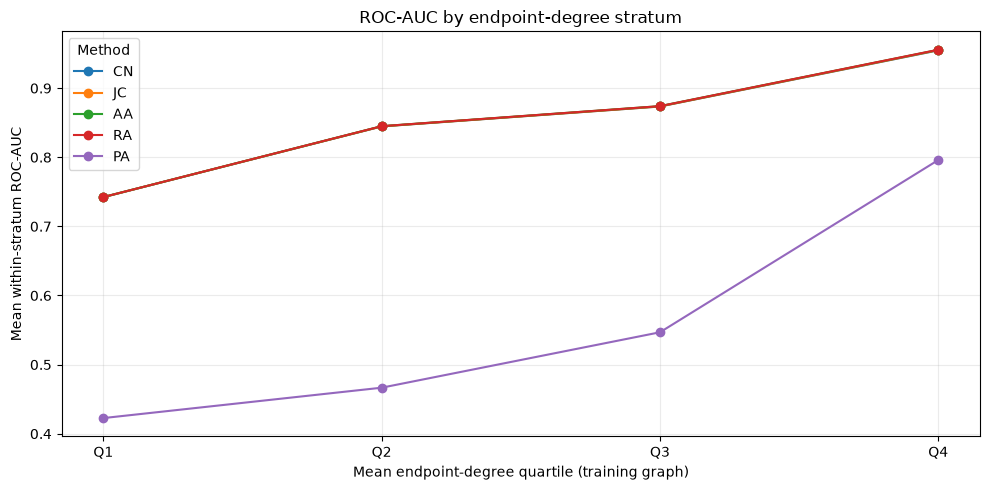

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))
for method in ALGORITHM_NAMES:
    subset = degree_performance_summary_df[
        degree_performance_summary_df["method"] == method
    ].sort_values("degree_stratum")
    ax.plot(
        subset["degree_stratum"],
        subset["roc_auc_mean"],
        marker="o",
        label=method,
    )
ax.set(title="ROC-AUC by endpoint-degree stratum",
       xlabel="Mean endpoint-degree quartile (training graph)",
       ylabel="Mean within-stratum ROC-AUC")
ax.legend(title="Method")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "degree_stratified_auc.png", dpi=180)
plt.show()

## 10. Runtime comparison, exports, and research interpretation

### 10.1 Per-candidate scoring time

The runtime column measures the scoring stage only, after a shared graph cache is built. Results can depend on CPU, Python version, graph iteration order, and system load. Report the machine and package versions with any runtime claims. Do not interpret small timing differences as robust unless measured across repeated runs on the same machine.

In [33]:
runtime_summary_df = (
    results_df[results_df["method"].isin(ALGORITHM_NAMES)]
    .groupby("method", as_index=False)
    .agg(
        runtime_mean_seconds=("scoring_seconds", "mean"),
        runtime_std_seconds=("scoring_seconds", "std"),
    )
    .sort_values("runtime_mean_seconds")
)
runtime_summary_df.round(6)

,method,runtime_mean_seconds,runtime_std_seconds
3,PA,0.007295,0.002368
1,CN,0.021237,0.007159
2,JC,0.023155,0.005782
4,RA,0.035733,0.006165
0,AA,0.037242,0.009021


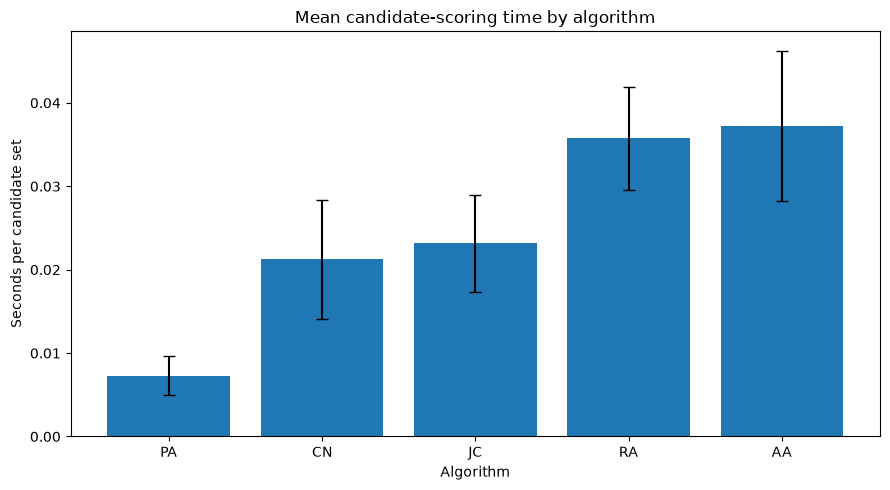

In [34]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    runtime_summary_df["method"],
    runtime_summary_df["runtime_mean_seconds"],
    yerr=runtime_summary_df["runtime_std_seconds"],
    capsize=4,
)
ax.set(title="Mean candidate-scoring time by algorithm",
       xlabel="Algorithm", ylabel="Seconds per candidate set")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "algorithm_runtime.png", dpi=180)
plt.show()

### 10.2 Export all results

The CSV files are the machine-readable research outputs. Figures are saved as PNG files. The notebook itself remains the executable record of methodology and analysis.

In [35]:
exports = {
    "primary_experiment_results.csv": results_df,
    "primary_experiment_summary.csv": summary_df,
    "friedman_tests.csv": friedman_df,
    "pairwise_wilcoxon_holm.csv": pairwise_df,
    "holdout_sensitivity_raw.csv": holdout_results_df,
    "holdout_sensitivity_summary.csv": holdout_summary_df,
    "negative_ratio_sensitivity_raw.csv": negative_ratio_results_df,
    "negative_ratio_sensitivity_summary.csv": negative_ratio_summary_df,
    "degree_strata_descriptive.csv": degree_strata_summary_df,
    "degree_stratified_performance_raw.csv": degree_performance_df,
    "degree_stratified_performance_summary.csv": degree_performance_summary_df,
    "runtime_summary.csv": runtime_summary_df,
}

for filename, frame in exports.items():
    frame.to_csv(TABLES_DIR / filename, index=False)

print(f"Saved {len(exports)} result tables to {TABLES_DIR}")
print(f"Saved figures to {FIGURES_DIR}")

Saved 12 result tables to D:\experimens\machine learning\graphtheory\results\tables
Saved figures to D:\experimens\machine learning\graphtheory\results\figures


### 10.3 Automatically generated summary of the observed benchmark

The following cell summarizes the result of the executed notebook. It does not hard-code any algorithm winner or performance value.

In [36]:
primary_algorithm_summary = summary_df[
    summary_df["method"].isin(ALGORITHM_NAMES)
].sort_values("roc_auc_mean", ascending=False)

winner_auc = primary_algorithm_summary.iloc[0]
winner_ap = summary_df[
    summary_df["method"].isin(ALGORITHM_NAMES)
].sort_values("average_precision_mean", ascending=False).iloc[0]
random_row = summary_df[summary_df["method"] == BASELINE_NAME].iloc[0]

print(
    f"Highest mean ROC-AUC: {winner_auc['method']} "
    f"({winner_auc['roc_auc_mean']:.4f} ± {winner_auc['roc_auc_std']:.4f})."
)
print(
    f"Highest mean Average Precision: {winner_ap['method']} "
    f"({winner_ap['average_precision_mean']:.4f} ± {winner_ap['average_precision_std']:.4f})."
)
print(
    f"Random baseline mean ROC-AUC: {random_row['roc_auc_mean']:.4f}; "
    f"mean AP: {random_row['average_precision_mean']:.4f}."
)

ra_aa = pairwise_df[
    (pairwise_df["metric"] == "roc_auc")
    & (
        ((pairwise_df["method_a"] == "RA") & (pairwise_df["method_b"] == "AA"))
        | ((pairwise_df["method_a"] == "AA") & (pairwise_df["method_b"] == "RA"))
    )
]
if not ra_aa.empty:
    print("RA versus AA ROC-AUC paired comparison:")
    print(ra_aa[[
        "mean_paired_difference_a_minus_b",
        "median_paired_difference_a_minus_b",
        "p_value_raw",
        "p_value_holm",
        "significant_holm_0_05",
    ]].to_string(index=False))

Highest mean ROC-AUC: RA (0.9054 ± 0.0036).
Highest mean Average Precision: RA (0.8249 ± 0.0065).
Random baseline mean ROC-AUC: 0.5027; mean AP: 0.0918.
RA versus AA ROC-AUC paired comparison:
 mean_paired_difference_a_minus_b  median_paired_difference_a_minus_b  p_value_raw  p_value_holm  significant_holm_0_05
                        -0.000041                           -0.000041     0.001953      0.019531                   True


### 10.4 Research discussion prompts

Use the actual generated values and plots to answer the following in your report:

1. Which method has the highest mean ROC-AUC? Is its margin over the next method practically meaningful?
2. Which method has the highest AP, and how does that ranking differ from ROC-AUC?
3. Are pairwise differences significant after Holm correction? Distinguish omnibus evidence from pairwise evidence.
4. How does holdout proportion affect the local-neighbourhood methods and PA?
5. How sensitive is AP to the negative-sampling ratio? Does ROC-AUC change in the same way?
6. Do methods behave differently in low-, medium-, and high-endpoint-degree strata?
7. Which method is fastest under the measured implementation and machine conditions?
8. How frequently do held-out positive links receive zero scores from each local method?

## 11. Limitations and validity considerations

1. **Static network:** The standard ca-GrQc edge list is an aggregated static co-authorship graph. This notebook performs retrospective missing-edge reconstruction, not future-time prediction.
2. **Binary edges:** A simple graph records whether two authors ever co-authored; it does not encode number of shared papers, dates, or collaboration strength.
3. **Clique projection:** A paper with multiple authors induces a clique in the projected author graph. Edges from the same paper can therefore be structurally dependent, and the edge list does not preserve paper identifiers needed for paper-level splitting.
4. **Negative-label uncertainty:** An unobserved pair is treated as a negative for this benchmark, but absence from the file does not prove that the pair could never collaborate.
5. **Sampling dependence:** AP and top-K metrics depend on the sampled negative ratio. Report that ratio beside every result.
6. **Single-network inference:** Ten random splits from one network are not ten independent networks. Statistical tests describe stability under the chosen resampling scheme and do not establish generalization to all collaboration networks.
7. **LCC selection:** The primary benchmark excludes the smaller components. Conclusions therefore apply primarily to the connected core.
8. **Runtime portability:** Runtime values are hardware- and implementation-dependent. Report environment details and repeat timing where small differences matter.

## 12. References

- J. Leskovec, J. Kleinberg, and C. Faloutsos, “Graph Evolution: Densification and Shrinking Diameters,” *ACM Transactions on Knowledge Discovery from Data*, 1(1), 2007. Dataset source and structural description: [SNAP ca-GrQc](https://snap.stanford.edu/data/ca-GrQc.html).
- D. Liben-Nowell and J. Kleinberg, “The Link-Prediction Problem for Social Networks,” *Journal of the American Society for Information Science and Technology*, 58(7), 2007, pp. 1019–1031.
- NetworkX documentation, [Graph algorithms](https://networkx.org/documentation/stable/reference/algorithms/link_prediction.html).

---